# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [10]:

import numpy as np
import pandas as pd
import matplotlib 
import matplotlib.pyplot as plt
import seaborn as sns

print(f"numpy version :{np.__version__}")
print(f"pandas version :{pd.__version__}")
print(f"matploy version :{matplotlib.__version__}")
print(f"seaborn version :{sns.__version__}")



np.random.seed(1)

numpy version :2.1.3
pandas version :2.2.3
matploy version :3.10.0
seaborn version :0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [12]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta =np.array([0.3, 0.7]) 
bias =0.5

# 1. Compute linear combination z
z =S @ theta + bias 

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5) 
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails 
predicted_spam = probabilities >= 0.5


In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities) 
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [16]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})


In [ ]:
# Auto graded cell (log)
# skip it

In [17]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

# Write your code here
idx_failed = rng.choice(log.index, size=12, replace=False)
log.loc[idx_failed, "failed_attempts"] = rng.integers(5, 11, size=12)

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [18]:
# Insert 10 missing values randomly
idx_missing = rng.choice(log.index, size=10, replace=False)
log.loc[idx_missing, "duration_min"] = np.nan
# Write your code here

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [19]:
# Write your code here
ru_log_at_least_five_attempts = log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)].shape[0]
print(ru_log_at_least_five_attempts)


1


In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [20]:
# Write your code here
user_max_failed_attempts = (
    log.groupby("user")["failed_attempts"]
    .sum()
    .sort_values(ascending=False)
)

print(user_max_failed_attempts)
print("User with the highest total:", user_max_failed_attempts.index[0])


user
karim     51
nour      45
ali       44
yacine    43
sara      36
Name: failed_attempts, dtype: int64
User with the highest total: karim


In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [21]:
# Write your code here
log["long_session"] = (log["duration_min"] > 30).astype(int)


In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

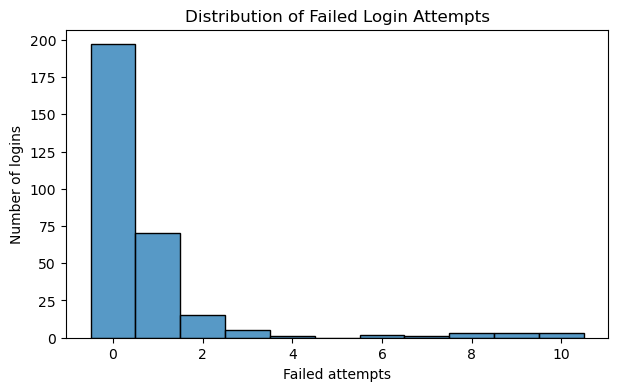

In [22]:
# Draw the histogram of failed_attempts.
# Write your code here
plt.figure(figsize=(7, 4))
sns.histplot(data=log, x="failed_attempts", bins=range(0, int(log["failed_attempts"].max()) + 2), discrete=True)
plt.title("Distribution of Failed Login Attempts")
plt.xlabel("Failed attempts")
plt.ylabel("Number of logins")
plt.show()

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [33]:
# Write your code here
 answer_q2 ="B"

IndentationError: unexpected indent (922323139.py, line 2)

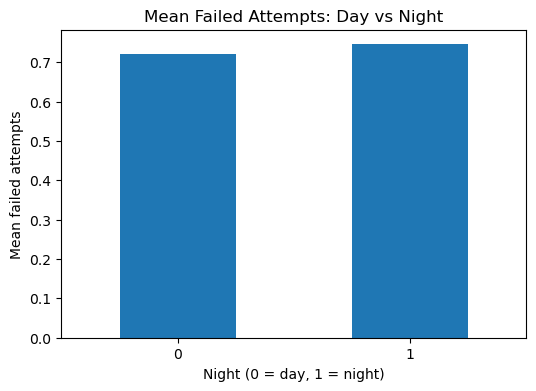

In [25]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

# Write your code here
# Create a night column: night is 1 from 22:00 to 05:59, otherwise 0
log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)

# Bar chart of the mean failed attempts for day and night logins
mean_failed_by_night = log.groupby("night")["failed_attempts"].mean()

plt.figure(figsize=(6, 4))
mean_failed_by_night.plot(kind="bar")
plt.title("Mean Failed Attempts: Day vs Night")
plt.xlabel("Night (0 = day, 1 = night)")
plt.ylabel("Mean failed attempts")
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [31]:
# Write your code here
answer_q1 = "X[:, 2] returns all rows from the third column of X as a one-dimensional array."
# Please write a sentence response instead of code

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [38]:
# Write your code here
answer_q2 = "df.isna().sum()"

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [37]:
# Write your code here
answer_q3 = "A box plot (boxplot), with country on the x-axis and failed_attempts on the y-axis."

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [36]:
# Write your code here
answer_q4 = "We scale features so that variables with larger numerical ranges do not dominate the model."

Commit the logins_clean.csv.(0.5 point)

In [35]:
# save the cleaned table in login_clean.csv
# Write your code here
log_clean = log.copy()
log_clean["duration_min"] = log_clean["duration_min"].fillna(log_clean["duration_min"].median())
log_clean.to_csv("logins_clean.csv", index=False)
print("Saved logins_clean.csv")

Saved logins_clean.csv


In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [34]:
# Write your code here
df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy()
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("X shape:", X.shape)
print("Scaled X shape:", X_scaled.shape)

X shape: (300, 4)
Scaled X shape: (300, 4)


In [ ]:
import numpy as np
import pandas as pd
